# Problem 3.2: Banked Car with Friction - Dimensionless Analysis

## Problem Statement
A car travels on a banked curve (angle $\beta$) with friction coefficient $\mu_s$. Find the range of speeds $v_{min}$ to $v_{max}$ to keep the car in circular motion without slipping.

**Physical Answer:**
$$v_{min} = \sqrt{\frac{gR(\sin\beta + \mu_s \cos\beta)}{\cos\beta + \mu_s \sin\beta}}$$

$$v_{max} = \sqrt{\frac{gR(\sin\beta + \mu_s \cos\beta)}{\cos\beta - \mu_s \sin\beta}}$$

## Dimensionless Analysis
The key insight is to use a characteristic speed scale: $v_* = \sqrt{gR}$

Define dimensionless speeds:
$$v_{min}^* = \frac{v_{min}}{\sqrt{gR}} = \sqrt{\frac{\sin\beta + \mu_s \cos\beta}{\cos\beta + \mu_s \sin\beta}}$$

$$v_{max}^* = \frac{v_{max}}{\sqrt{gR}} = \sqrt{\frac{\sin\beta + \mu_s \cos\beta}{\cos\beta - \mu_s \sin\beta}}$$

**Key Finding:** The dimensionless speed range depends ONLY on $\beta$ and $\mu_s$, not on $g$ or $R$ individually!

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 10)
plt.rcParams['font.size'] = 11

## Part 1: Dimensionless Speed Functions

In [2]:
def v_min_dimensionless(beta_rad, mu_s):
    """
    Dimensionless minimum speed for banked car with friction.
    v_min* = sqrt((sin(β) + μₛ cos(β)) / (cos(β) + μₛ sin(β)))
    """
    numerator = np.sin(beta_rad) + mu_s * np.cos(beta_rad)
    denominator = np.cos(beta_rad) + mu_s * np.sin(beta_rad)
    return np.sqrt(numerator / denominator)

def v_max_dimensionless(beta_rad, mu_s):
    """
    Dimensionless maximum speed for banked car with friction.
    v_max* = sqrt((sin(β) + μₛ cos(β)) / (cos(β) - μₛ sin(β)))
    """
    numerator = np.sin(beta_rad) + mu_s * np.cos(beta_rad)
    denominator = np.cos(beta_rad) - mu_s * np.sin(beta_rad)
    # Avoid division by zero
    denominator = np.where(denominator > 0, denominator, np.nan)
    return np.sqrt(numerator / denominator)

def v_physical(beta_rad, mu_s, R, g):
    """
    Convert dimensionless speeds to physical speeds.
    v = v* * sqrt(gR)
    """
    scale = np.sqrt(g * R)
    v_min_star = v_min_dimensionless(beta_rad, mu_s)
    v_max_star = v_max_dimensionless(beta_rad, mu_s)
    return v_min_star * scale, v_max_star * scale

print("Functions defined successfully.")

Functions defined successfully.


## Part 2: Universal Dimensionless Behavior

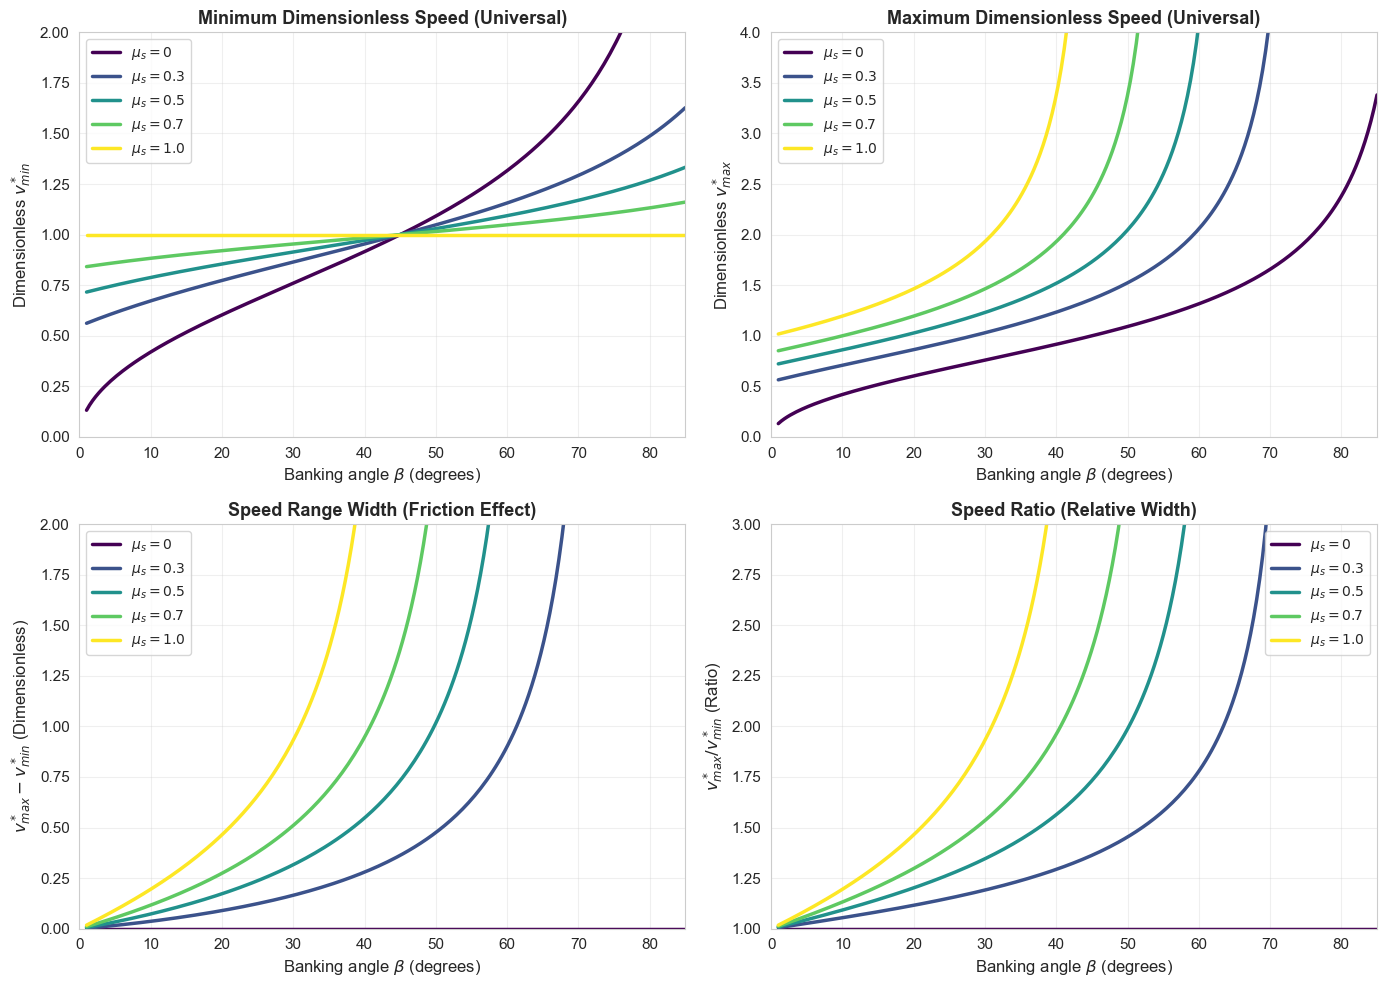


KEY INSIGHT: These curves are UNIVERSAL!
They apply to Earth, Moon, Jupiter, and any planet.
They apply to any curve radius R.


In [3]:
# Create range of banking angles
beta_deg = np.linspace(1, 85, 200)
beta_rad = np.radians(beta_deg)

# Different friction coefficients
mu_values = [0, 0.3, 0.5, 0.7, 1.0]
colors = plt.cm.viridis(np.linspace(0, 1, len(mu_values)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ===== Top Left: v_min* vs β for different μₛ =====
ax = axes[0, 0]
for mu, color in zip(mu_values, colors):
    v_min_star = v_min_dimensionless(beta_rad, mu)
    ax.plot(beta_deg, v_min_star, linewidth=2.5, label=f'$\mu_s = {mu}$', color=color)

ax.set_xlabel('Banking angle $\\beta$ (degrees)', fontsize=12)
ax.set_ylabel('Dimensionless $v_{min}^*$', fontsize=12)
ax.set_title('Minimum Dimensionless Speed (Universal)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 85])
ax.set_ylim([0, 2])

# ===== Top Right: v_max* vs β for different μₛ =====
ax = axes[0, 1]
for mu, color in zip(mu_values, colors):
    v_max_star = v_max_dimensionless(beta_rad, mu)
    ax.plot(beta_deg, v_max_star, linewidth=2.5, label=f'$\mu_s = {mu}$', color=color)

ax.set_xlabel('Banking angle $\\beta$ (degrees)', fontsize=12)
ax.set_ylabel('Dimensionless $v_{max}^*$', fontsize=12)
ax.set_title('Maximum Dimensionless Speed (Universal)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 85])
ax.set_ylim([0, 4])

# ===== Bottom Left: Speed Range (v_max* - v_min*) =====
ax = axes[1, 0]
for mu, color in zip(mu_values, colors):
    v_min_star = v_min_dimensionless(beta_rad, mu)
    v_max_star = v_max_dimensionless(beta_rad, mu)
    speed_range = v_max_star - v_min_star
    ax.plot(beta_deg, speed_range, linewidth=2.5, label=f'$\mu_s = {mu}$', color=color)

ax.set_xlabel('Banking angle $\\beta$ (degrees)', fontsize=12)
ax.set_ylabel('$v_{max}^* - v_{min}^*$ (Dimensionless)', fontsize=12)
ax.set_title('Speed Range Width (Friction Effect)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 85])
ax.set_ylim([0, 2])

# ===== Bottom Right: Ratio v_max*/v_min* =====
ax = axes[1, 1]
for mu, color in zip(mu_values, colors):
    v_min_star = v_min_dimensionless(beta_rad, mu)
    v_max_star = v_max_dimensionless(beta_rad, mu)
    ratio = v_max_star / v_min_star
    ax.plot(beta_deg, ratio, linewidth=2.5, label=f'$\mu_s = {mu}$', color=color)

ax.set_xlabel('Banking angle $\\beta$ (degrees)', fontsize=12)
ax.set_ylabel('$v_{max}^* / v_{min}^*$ (Ratio)', fontsize=12)
ax.set_title('Speed Ratio (Relative Width)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 85])
ax.set_ylim([1, 3])

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("KEY INSIGHT: These curves are UNIVERSAL!")
print("They apply to Earth, Moon, Jupiter, and any planet.")
print("They apply to any curve radius R.")
print("="*70)

## Part 3: Scaling to Physical Scenarios

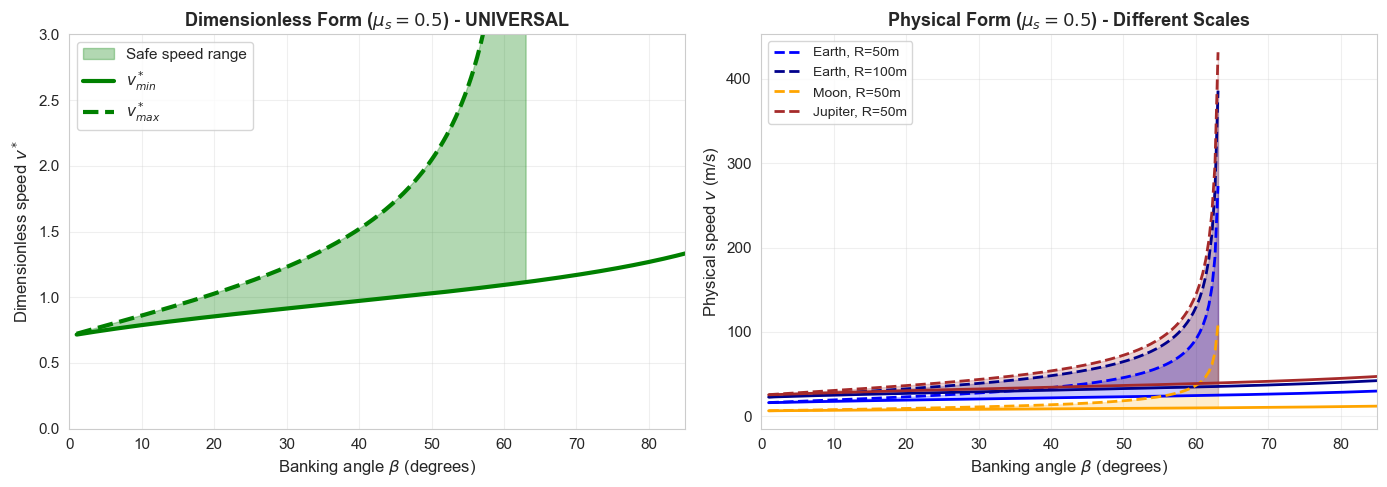


Physical speeds for μₛ = 0.5 and various scenarios:


In [4]:
# Define physical scenarios
scenarios = [
    {'name': 'Earth, R=50m',  'R': 50,  'g': 10, 'color': 'blue'},
    {'name': 'Earth, R=100m', 'R': 100, 'g': 10, 'color': 'darkblue'},
    {'name': 'Moon, R=50m',   'R': 50,  'g': 1.6, 'color': 'orange'},
    {'name': 'Jupiter, R=50m','R': 50,  'g': 25, 'color': 'brown'},
]

mu_s = 0.5  # Fixed friction coefficient

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ===== Left: Dimensionless (Universal) =====
ax = axes[0]
v_min_star = v_min_dimensionless(beta_rad, mu_s)
v_max_star = v_max_dimensionless(beta_rad, mu_s)

ax.fill_between(beta_deg, v_min_star, v_max_star, alpha=0.3, color='green', label='Safe speed range')
ax.plot(beta_deg, v_min_star, 'g-', linewidth=3, label='$v_{min}^*$')
ax.plot(beta_deg, v_max_star, 'g--', linewidth=3, label='$v_{max}^*$')

ax.set_xlabel(r'Banking angle $\beta$ (degrees)', fontsize=12)
ax.set_ylabel(r'Dimensionless speed $v^*$', fontsize=12)
ax.set_title(f'Dimensionless Form ($\mu_s = {mu_s}$) - UNIVERSAL', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
ax.set_xlim([0, 85])
ax.set_ylim([0, 3])

# ===== Right: Physical Scenarios =====
ax = axes[1]

for scenario in scenarios:
    v_min_phys, v_max_phys = v_physical(beta_rad, mu_s, scenario['R'], scenario['g'])
    ax.fill_between(beta_deg, v_min_phys, v_max_phys, alpha=0.2, color=scenario['color'])
    ax.plot(beta_deg, v_min_phys, linewidth=2, color=scenario['color'], linestyle='-')
    ax.plot(beta_deg, v_max_phys, linewidth=2, color=scenario['color'], linestyle='--', 
            label=scenario['name'])

ax.set_xlabel(r'Banking angle $\beta$ (degrees)', fontsize=12)
ax.set_ylabel(r'Physical speed $v$ (m/s)', fontsize=12)
ax.set_title(f'Physical Form ($\mu_s = {mu_s}$) - Different Scales', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10, loc='upper left')
ax.set_xlim([0, 85])

plt.tight_layout()
plt.show()

print(f"\nPhysical speeds for μₛ = {mu_s} and various scenarios:")

## Part 4: Numerical Comparison Table

In [5]:
# Create detailed comparison table
angles = [15, 30, 45, 60]
mu_frictions = [0.3, 0.5, 0.7]

print("\n" + "="*90)
print("DIMENSIONLESS SPEED RANGE: v* = v / sqrt(gR)")
print("(Independent of g and R - UNIVERSAL!)")
print("="*90)

for mu_s in mu_frictions:
    print(f"\nFriction coefficient μₛ = {mu_s}")
    print("-" * 90)
    print(f"{'β (°)':<8} {'v_min^* ':<15} {'v_max^* ':<15} {'Range':<15} {'Ratio':<10}")
    print("-" * 90)
    
    for angle in angles:
        beta_r = np.radians(angle)
        v_min_star = v_min_dimensionless(beta_r, mu_s)
        v_max_star = v_max_dimensionless(beta_r, mu_s)
        range_val = v_max_star - v_min_star
        ratio = v_max_star / v_min_star
        
        print(f"{angle:<8} {v_min_star:<15.4f} {v_max_star:<15.4f} {range_val:<15.4f} {ratio:<10.3f}")

print("\n" + "="*90)
print("PHYSICAL SPEED RANGE: v = v* × sqrt(gR)")
print("(Scales with gravitational field and curve radius)")
print("="*90)

mu_s = 0.5
print(f"\nFriction coefficient μₛ = {mu_s}")
print("-" * 90)

for scenario in scenarios:
    print(f"\n{scenario['name']} (g = {scenario['g']} m/s², R = {scenario['R']} m)")
    print("-" * 50)
    print(f"{'β (°)':<8} {'v_min (m/s)':<15} {'v_max (m/s)':<15} {'Range (m/s)':<15}")
    print("-" * 50)
    
    for angle in angles:
        beta_r = np.radians(angle)
        v_min, v_max = v_physical(beta_r, mu_s, scenario['R'], scenario['g'])
        range_val = v_max - v_min
        
        print(f"{angle:<8} {v_min:<15.2f} {v_max:<15.2f} {range_val:<15.2f}")


DIMENSIONLESS SPEED RANGE: v* = v / sqrt(gR)
(Independent of g and R - UNIVERSAL!)

Friction coefficient μₛ = 0.3
------------------------------------------------------------------------------------------
β (°)    v_min^*         v_max^*         Range           Ratio     
------------------------------------------------------------------------------------------
15       0.7250          0.7859          0.0608          1.084     
30       0.8648          1.0301          0.1654          1.191     
45       1.0000          1.3628          0.3628          1.363     
60       1.1564          2.0567          0.9003          1.779     

Friction coefficient μₛ = 0.5
------------------------------------------------------------------------------------------
β (°)    v_min^*         v_max^*         Range           Ratio     
------------------------------------------------------------------------------------------
15       0.8229          0.9417          0.1187          1.144     
30       0.914

## Part 5: Scaling Demonstration

In [6]:
# Show how physical speeds scale from dimensionless values
print("\n" + "="*80)
print("SCALING DEMONSTRATION: From Dimensionless to Physical")
print("="*80)

mu_s = 0.5
angle = 45  # degrees
beta_r = np.radians(angle)

# Get dimensionless values
v_min_star = v_min_dimensionless(beta_r, mu_s)
v_max_star = v_max_dimensionless(beta_r, mu_s)

print(f"\nFor β = {angle}° and μₛ = {mu_s}:")
print(f"  v_min^* = {v_min_star:.4f}")
print(f"  v_max^* = {v_max_star:.4f}")
print(f"\nFormula: v = v^* × √(gR)")
print("\n" + "-"*80)
print(f"{'Scenario':<25} {'Scale √(gR)':<20} {'v_min':<15} {'v_max':<15}")
print("-"*80)

for scenario in scenarios:
    scale = np.sqrt(scenario['g'] * scenario['R'])
    v_min = v_min_star * scale
    v_max = v_max_star * scale
    print(f"{scenario['name']:<25} {scale:<20.2f} {v_min:<15.2f} {v_max:<15.2f}")

print("-"*80)
print("\nNotice: Same dimensionless values scale to different physical values!")
print("Scaling factor = √(gR) = √(gravity × radius)")


SCALING DEMONSTRATION: From Dimensionless to Physical

For β = 45° and μₛ = 0.5:
  v_min^* = 1.0000
  v_max^* = 1.7321

Formula: v = v^* × √(gR)

--------------------------------------------------------------------------------
Scenario                  Scale √(gR)          v_min           v_max          
--------------------------------------------------------------------------------
Earth, R=50m              22.36                22.36           38.73          
Earth, R=100m             31.62                31.62           54.77          
Moon, R=50m               8.94                 8.94            15.49          
Jupiter, R=50m            35.36                35.36           61.24          
--------------------------------------------------------------------------------

Notice: Same dimensionless values scale to different physical values!
Scaling factor = √(gR) = √(gravity × radius)


## Part 6: Effect of Friction Coefficient

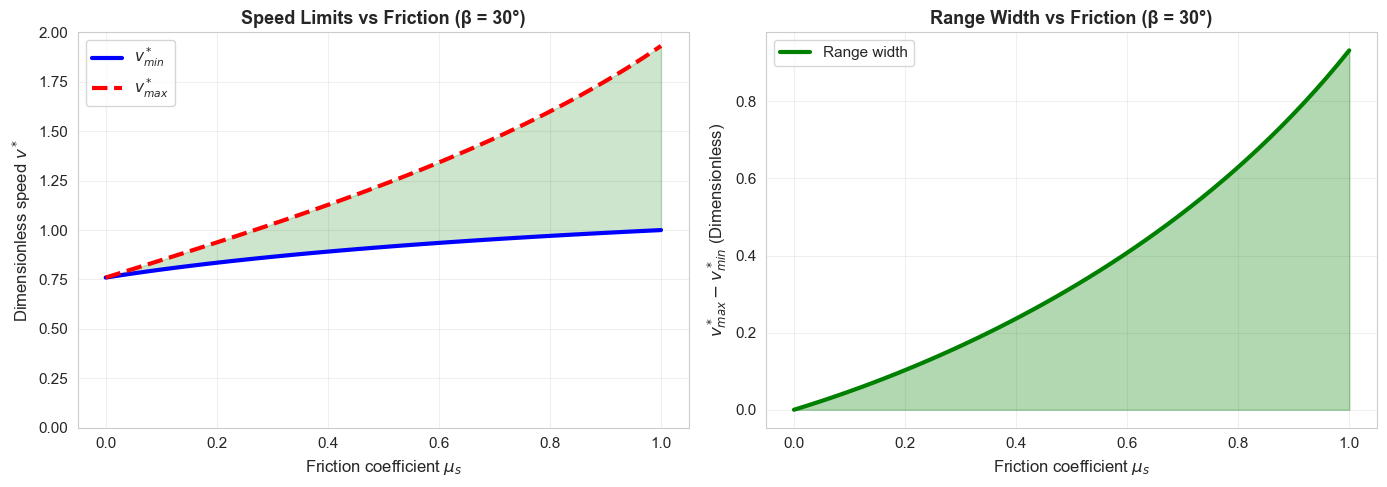


Friction Effect at β = 30°:
------------------------------------------------------------
μₛ       v_min^*         v_max^*         Range          
------------------------------------------------------------
0        0.7598          0.7598          0.0000         
0.3      0.8648          1.0301          0.1654         
0.5      0.9143          1.2307          0.3163         
0.7      0.9538          1.4641          0.5104         
1.0      1.0000          1.9319          0.9319         


In [7]:
# Show how friction affects the speed range
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mu_values = np.linspace(0, 1, 50)
beta_test = 30  # Fixed banking angle
beta_r = np.radians(beta_test)

v_min_values = [v_min_dimensionless(beta_r, mu) for mu in mu_values]
v_max_values = [v_max_dimensionless(beta_r, mu) for mu in mu_values]
range_values = [v_max_values[i] - v_min_values[i] for i in range(len(mu_values))]

# ===== Left: Speed limits vs friction =====
ax = axes[0]
ax.plot(mu_values, v_min_values, 'b-', linewidth=3, label='$v_{min}^*$')
ax.plot(mu_values, v_max_values, 'r--', linewidth=3, label='$v_{max}^*$')
ax.fill_between(mu_values, v_min_values, v_max_values, alpha=0.2, color='green')

ax.set_xlabel('Friction coefficient $\mu_s$', fontsize=12)
ax.set_ylabel('Dimensionless speed $v^*$', fontsize=12)
ax.set_title(f'Speed Limits vs Friction (β = {beta_test}°)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
ax.set_ylim([0, 2])

# ===== Right: Speed range width vs friction =====
ax = axes[1]
ax.plot(mu_values, range_values, 'g-', linewidth=3, label='Range width')
ax.fill_between(mu_values, 0, range_values, alpha=0.3, color='green')

ax.set_xlabel('Friction coefficient $\mu_s$', fontsize=12)
ax.set_ylabel('$v_{max}^* - v_{min}^*$ (Dimensionless)', fontsize=12)
ax.set_title(f'Range Width vs Friction (β = {beta_test}°)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

print(f"\nFriction Effect at β = {beta_test}°:")
print("-" * 60)
print(f"{'μₛ':<8} {'v_min^*':<15} {'v_max^*':<15} {'Range':<15}")
print("-" * 60)
for mu in [0, 0.3, 0.5, 0.7, 1.0]:
    v_min_star = v_min_dimensionless(beta_r, mu)
    v_max_star = v_max_dimensionless(beta_r, mu)
    range_val = v_max_star - v_min_star
    print(f"{mu:<8} {v_min_star:<15.4f} {v_max_star:<15.4f} {range_val:<15.4f}")

## Key Insights

### 1. **Dimensionless Speed Range is Universal**
The curves $v_{min}^*$ and $v_{max}^*$ depend ONLY on $\beta$ and $\mu_s$:
- Identical on Earth, Moon, and Jupiter
- Identical for small curves (R=50m) and large curves (R=100m)
- These are the "universal physics" of banked curves with friction

### 2. **Physical Speeds Scale by $\sqrt{gR}$**
To get actual speeds: $v = v^* \cdot \sqrt{gR}$
- Stronger gravity → higher physical speeds
- Larger radius → higher physical speeds
- Same shape, different scale

### 3. **Friction Expands the Safe Range**
- At low speeds: friction acts UP the slope → allows slower speeds
- At high speeds: friction acts DOWN the slope → limits maximum speeds
- More friction → wider safe speed range
- Zero friction: $v_{min}^* = v_{max}^* = \sqrt{\tan\beta}$ (single ideal speed)

### 4. **Banking Angle Effects**
- Steeper banking → higher speeds required
- Steeper banking + high friction → very wide speed range
- Nearly flat ($\beta \to 0$) → narrow range, slow speeds

### 5. **Engineering Applications**
- Design a curve on Earth at one radius
- Use dimensionless form to predict behavior at different radius
- Use dimensionless form to predict behavior on different planets
- Just scale by $\sqrt{gR}$!